<div align="center">

<img src="images/isamm.png" alt="ISAMM Logo" width="150">

# RAG & Agentic AI
### From Grounding to Adaptive Retrieval

**Academic Presentation & Practical Exploration**

---

**Author:** Yosr Meddah

**Course:** Machine Learning (ML)  
**Institution:** Higher Institute of Arts and Multimedia of Manouba (ISAMM)  
**Academic Year:** 2026–2027

---

</div>

## Context and Motivation

This notebook was developed as a practical extension of an academic presentation delivered as part of the **Machine Learning (ML)** course at ISAMM.

For this presentation, I chose to explore **Retrieval-Augmented Generation (RAG)** and **Agentic AI**, two important concepts at the intersection of machine learning and modern AI application development.

The objective was to go beyond theoretical definitions and investigate how these approaches work in practice, how they address some limitations of Large Language Models (LLMs), and what engineering considerations arise when building reliable AI-powered systems.




**What I wanted to understand**
1. How lexical and dense retrieval can complement one another.
2. How chunking and the value of *k* influence retrieval quality.
3. How a ReAct-style loop coordinates tools and observations.
4. Whether targeted retrieval can find missing information without simply increasing context size.
5. What additional complexity costs in latency, tokens, and reliability.



---

# 1. Introduction: why an LLM alone is not enough

## 1.1 An LLM produces plausible text, not truth

An LLM is an autoregressive model: it learns the probability distribution of the next token over an extensive training corpus, generating responses by sampling from that distribution.

Nothing in the training objective mandates factual truth. The objective simply optimizes for likelihood. A false but fluent sentence is an optimal outcome from the loss function's perspective. The model **compresses** knowledge into weights rather than archiving verbatim records: rare, recent, or precise facts (numbers, IDs, specific dates) are the first to degrade. Crucially, the model lacks a **ground-truth validation mechanism**: it cannot verify a claim against an authoritative source, only produce a continuation consistent with its active context.

![Why a plain LLM is not enough](images/why_llm_not_enough.png)

Three distinct families of hallucination:

| Type | Definition | Typical Example |
|---|---|---|
| **Factual** | Explicitly false claim about external reality | "GDPR requires 48-hour breach notification" (it is 72 hours) |
| **Attribution** | Fabricated or misattributed source or citation | Citing a plausible-sounding but non-existent RFC or paper |
| **Reasoning** | Invalid logical deduction framed with high confidence | Valid mathematical premises leading to an erroneous conclusion |

**Why the model "prefers" to answer:** Instruction-tuned assistants are heavily rewarded for helpfulness, creating a strong behavioral bias to answer rather than abstain. Three engineering imperatives follow:
1. **Abstention must be explicitly enabled and rewarded** in system prompts.
2. **Citations must be verifiable** using machine-readable passage IDs.
3. **Lowering temperature reduces output variance, not factual ignorance.**

## 1.2 The four limits that motivate RAG

| Limit | Observable Symptom | Engineering Response |
|---|---|---|
| **Frozen knowledge** (cutoff) | Ignores facts or events occurring after pretraining | Grounding via fresh external retrieval (RAG) |
| **Missing private data** | Hallucinates internal policies, proprietary APIs, or contracts | Retrieval over access-controlled internal corpora |
| **Factual precision** | Generates plausible numbers, IDs, or regulatory citations | Grounded RAG with strict passage citation and verification |
| **Complex multi-step tasks** | Loses track of constraints across dependent steps | Agentic workflows: planning, tool use, and evaluation loops |

**The context window is not memory.** Expanding context windows to 1M+ tokens does not eliminate the need for retrieval:
- **Cost and latency:** Attention computation scales quadratically or chunk-linearly; passing megatokens on every query is economically and operationally prohibitive.
- **Attention degradation (*Lost in the Middle*):** Information located in the middle of long contexts suffers significantly lower retrieval accuracy compared to tokens at the beginning or end.
- **Selection is still required:** Even with infinite context, selecting which authoritative data to inject remains an information retrieval problem.

## 1.3 Four levers, not one

| Lever | What it modifies | Primary Strength | Key Limitation | Update Cost |
|---|---|---|---|---|
| **Fine-tuning** | Model weights | Style, tone, domain vocabulary, task formatting | Unreliable for factual recall; catastrophic forgetting | High (Retraining) |
| **RAG** | Dynamic input context | Factual grounding, freshness, verifiable provenance, ACLs | Bounded by retrieval recall and context length | Low (Reindexing) |
| **Long context** | Context size | Simple architecture; handles unstructured long inputs | High cost and latency; attention dilution | Zero (Per query) |
| **Agents** | Control flow | Autonomous multi-step problem solving, tool use, recovery | Compounding error rates; non-deterministic latency | Low to Medium |

## 1.4 Why RAG: five gains, four trade-offs

**Five fundamental gains:**
1. **Freshness:** Updating data requires adding or updating index entries, avoiding expensive model fine-tuning.
2. **Access Control (ACL):** Document-level security filters can be applied at search time so users only retrieve authorized documents.
3. **Verifiable Citations:** Responses can be attributed to specific passage IDs, enabling instant human verification.
4. **Separation of Concerns:** Factual knowledge is decoupled from linguistic reasoning capabilities.
5. **Auditability:** Grounded answers can be traced directly to indexed source chunks.

**Four engineering trade-offs:**
1. **System Complexity:** Introduces ingestion pipelines, parsers, chunking strategies, embeddings, vector databases, and rerankers.
2. **Latency Overhead:** Adds search, network, and context serialization time to every generation pass.
3. **Context Noise:** Retrieving irrelevant or distracting chunks degrades generation quality.
4. **Retrieval Failure Modes:** If retrieval fails to fetch the right passage, the generator will either hallucinate or fail to answer.

## 1.5 Why agentic: when one pass is not enough

Classic RAG is strictly **linear and feed-forward**: Question $\rightarrow$ Retrieve top-$k$ $\rightarrow$ Generate answer.

This architecture works well for direct, single-fact lookup questions. However, it fails in three common operational scenarios:
1. **Multi-hop questions:** Answering question $A$ requires discovering fact $B$, which reveals the need to look up fact $C$. A single search pass cannot identify the subsequent dependencies.
2. **Retrieval failure & ambiguity:** If the initial search query is poorly phrased or returns irrelevant distractors, classic RAG has no mechanism to critique the retrieved content, reformulate the query, or try another source.
3. **Complex multi-step actions:** When answering involves querying documentation, calculating numerical values, and verifying results, an autonomous control loop is necessary.

## 1.6 Core Principles: Grounding, Autonomy, and Parsimony

1. **Grounding before autonomy:** Never build an autonomous agent before ensuring that your baseline retrieval index returns relevant, clean, and well-ranked information.
2. **Autonomy carries an operational cost:** Agents pay for quality with latency, token consumption, and non-determinism. Simple single-turn queries should never trigger a multi-turn agentic loop.
3. **Parsimony in design:** The optimal production architecture is always the simplest one that satisfies your accuracy and recall thresholds. Start with baseline RAG, measure failure modes rigorously, and introduce agentic iteration only where the data proves it is needed.


---

# 2. Understanding how RAG works

## 2.1 Two memories, one model

A RAG system pairs two distinct forms of memory:
- **Parametric memory:** The weights of the pre-trained neural network. Compressed, static, broad, but prone to hallucination and unable to update without retraining.
- **Non-parametric memory:** An external, structured index of documents (vector store, inverted index, graph). Fresh, dynamic, auditable, and easily updated or access-controlled.

During generation, non-parametric memory provides authoritative factual context, while parametric memory provides linguistic synthesis, reasoning, and formatting.

![Agent memory types](images/memory_types.png)

## 2.2 The original architecture: Lewis et al. (2020)

In *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks* (NeurIPS 2020), Lewis et al. formalized two distinct retrieval-augmented generation formulations:
- **RAG-Sequence:** The model retrieves top-$k$ documents once for the entire sequence, conditioning generation on the same fixed context throughout.
- **RAG-Token:** The model dynamically marginalizes over retrieved documents at every generated token, allowing different documents to inform different parts of the output.

Modern commercial RAG implementations predominantly adapt the **RAG-Sequence** paradigm due to its lower computational latency and compatibility with standard autoregressive LLMs.

![RAG architecture](images/rag_architecture.png)

## 2.3 The modern pipeline, in ten steps

Production RAG involves ten discrete pipeline stages:

![The RAG pipeline in ten steps](images/rag_pipeline_10steps.png)

1. **Ingest:** Collect documents from diverse sources (Markdown, PDFs, API docs, Confluence, databases).
2. **Parse:** Extract clean text, structural headers, tables, and metadata while discarding presentation artifacts.
3. **Clean:** Normalize whitespace, strip boilerplate, clean unicode characters, and resolve encoding issues.
4. **Chunk:** Segment documents into semantic, digestible units balancing granularity with context retention.
5. **Embed:** Convert textual chunks into dense vector representations capturing semantic meaning.
6. **Index:** Build fast search structures (HNSW for vectors, inverted indexes for BM25 keyword search).
7. **Retrieve:** Execute sparse, dense, or hybrid queries to fetch candidate passages for an input question.
8. **Rerank:** Score candidates with a cross-encoder or reciprocal rank fusion to prioritize true relevance.
9. **Assemble:** Construct the final prompt containing the user query, instructions, and retrieved context.
10. **Generate:** Prompt the LLM to synthesize an accurate, grounded response with verifiable citations.

## 2.4 The running corpus

We now instantiate the running technical documentation of **NimbusDB**.


### A note on the implementation choices

I deliberately keep the first version small and local. The goal is to make the retrieval pipeline inspectable: I can see the documents, chunks, scores, and selected passages without depending on a hosted vector database or an external embedding API.

That choice is useful for learning, but it comes with a trade-off. The dense component uses **LSA**, a lightweight latent-semantic approximation, rather than a modern pretrained embedding model. I therefore treat it as a teaching baseline—not as a substitute for production-grade semantic embeddings.

As you read on, keep one question in mind: *is a retrieval result useful because its score is high, or because it contains the evidence needed to answer the question?*

In [ ]:
# --- Imports, configurations, and safe execution settings (100% offline) ---
import re
import math
import unicodedata
import ast
import operator
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# Configure pandas and matplotlib for readable inline displays
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print("numpy", np.__version__, "| pandas", pd.__version__, "| environment ready (offline mode).")


numpy 2.3.5 | pandas 2.2.3 | environment ready (offline mode).


In [ ]:
# --- NimbusDB corpus: 14 technical documentation excerpts ---
DOCS = [
    {"id": "auth-keys", "title": "API keys and authentication",
     "text": "NimbusDB authenticates every request via an API key passed in the "
             "Authorization: Bearer <key> header. Keys are scoped per project and per environment "
             "(dev, staging, prod). A compromised key must be revoked immediately from the admin "
             "console. Read-only keys can only execute GET queries and cannot write or delete data."},
    {"id": "rotation-procedure", "title": "Zero-downtime key rotation procedure",
     "text": "To rotate a key without service interruption: 1) create a new key in the console; "
             "2) deploy the new key on your servers; 3) verify traffic uses the new key; "
             "4) revoke the old key. The old key stays valid for a 24-hour grace period after "
             "revocation, giving instances time to update."},
    {"id": "rotation-inflight", "title": "In-flight requests during rotation",
     "text": "Requests already running at rotation time are not interrupted. They finish with "
             "the key used when issued. New requests presented with a key revoked more than 24 hours "
             "ago are rejected with 401 invalid_key. For long jobs (exports, indexing), wait for "
             "the job to finish before revoking."},
    {"id": "rate-limits", "title": "Rate limits and quotas",
     "text": "By default a project has 600 requests per minute and a burst of 1200 requests "
             "over 10 seconds. Limits are applied per project and per region. On overflow the API returns "
             "HTTP 429 rate_limited with a Retry-After header giving the seconds to wait. "
             "X-RateLimit-Remaining and X-RateLimit-Reset headers let you anticipate."},
    {"id": "retry-backoff", "title": "Recommended retry policy",
     "text": "Use exponential backoff with jitter: 500 ms base, factor 2, 30 s cap, max 5 attempts. "
             "Only retry idempotent errors (GET, PUT, DELETE) and codes 429, 500, 502, 503, 504. "
             "Errors 400 and 401 must never be retried. Jitter avoids synchronized retry storms "
             "across instances."},
    {"id": "error-codes", "title": "API error codes",
     "text": "401 invalid_key: missing, invalid or revoked key. 403 insufficient_scope: key lacks "
             "the required scope. 404 not_found. 409 conflict: concurrent write. 429 rate_limited: "
             "rate limit exceeded. 503 unavailable: maintenance or regional overload. Each error "
             "returns a JSON body with a request_id to give support."},
    {"id": "regions", "title": "Regions and data residency",
     "text": "NimbusDB is available in eu-west-1 (Paris) and us-east-1 (Virginia). Data stays in "
             "the project region; no cross-region replication without explicit activation. Backups "
             "are stored in the same region. For regulated workloads choose eu-west-1 and enable "
             "encryption with a customer-managed key (BYOK)."},
    {"id": "backups", "title": "Backups and restore",
     "text": "Continuous backups allow point-in-time restore (PITR) over the last 7 days. Daily "
             "snapshots are kept 30 days. Restore always creates a new instance; it never replaces "
             "the existing one. RPO is 5 minutes, RTO 30 minutes for a standard instance."},
    {"id": "quotas", "title": "Quotas and storage limits",
     "text": "Each project has 1 TB of storage and 10 million documents by default. Quotas can be "
             "raised from the console. Collections are limited to 100 per project. Deleted documents "
             "stay in the trash for 30 days."},
    {"id": "sdk-python", "title": "Python client: timeouts and connection pool",
     "text": "The Python SDK accepts timeout (default 30 s), max_retries (default 2) and pool_size "
             "(default 20). For batch processing, reuse a single client instance to share the "
             "connection pool. The SDK automatically backs off on 429 and 503 errors."},
    {"id": "webhooks", "title": "Webhooks and signature",
     "text": "Webhooks are signed with a shared secret (HMAC-SHA256) in the X-Nimbus-Signature "
             "header. Always verify the signature before processing the event. Failed deliveries "
             "are retried 5 times with exponential backoff over 24 hours."},
    {"id": "sla", "title": "Service levels (SLA)",
     "text": "SLA is 99.9% monthly availability for Standard plans and 99.95% for Enterprise. "
             "Planned maintenance is announced 72 hours ahead and excluded from the calculation. "
             "Service credits must be claimed within 30 days."},
    {"id": "pagination", "title": "Result pagination",
     "text": "List endpoints use cursor pagination. The limit parameter accepts 1 to 100 items "
             "(default 20). The next_cursor field is absent when there are no more results. Do not "
             "build page-number pagination: order is not guaranteed."},
    {"id": "vector-search", "title": "Vector search and indexes",
     "text": "Each collection can enable an HNSW vector index. Parameters M and ef_construction "
             "control recall and build time; ef_search controls the latency/recall trade-off at "
             "query time. Embeddings of dimension 1024 are accepted. An HNSW index consumes about "
             "1.5 times the vector size in memory."},
]
DOC_BY_ID = {d["id"]: d for d in DOCS}

# English stop words list for tokenization
STOP = set("a an the and or but if because as what when where how which who whom this that these those "
           "am is are was were be been being have has had having do does did doing would should could ought "
           "i you he she it we they me him her us them my your his its our their mine yours hers ours theirs "
           "to in of for on with at by from up down into over under again further then once".split())

def fold(s):
    '''Lowercase without accents: 'Revocation' -> 'revocation'.'''
    s = unicodedata.normalize("NFD", s.lower())
    return "".join(c for c in s if unicodedata.category(c) != "Mn")

def tokenize(text):
    text = fold(text)
    text = re.sub(r"[^a-z0-9_\-\s]", " ", text)
    return [t for t in text.split() if len(t) > 1 and t not in STOP]

print(f"{len(DOCS)} technical documents loaded, {sum(len(d['text'].split()) for d in DOCS)} total words.")
print("Tokenization example:", tokenize("Revoke the old key after 24 hours")[:6])


14 technical documents loaded, 584 total words.
Tokenization example: ['revoke', 'old', 'key', 'after', '24', 'hours']


## 2.5 Chunking: the most underestimated decision

How documents are chunked determines what the retriever can find. If a chunk is too small, it loses necessary contextual meaning; if too large, specific facts get diluted inside dense vector representations.

![Chunking strategies](images/chunking.png)

**Four classical chunking strategies:**

| Strategy | Principle | Ideal Use Case | Trade-off |
|---|---|---|---|
| **Fixed size + overlap** | Fixed token window (e.g. 500 tokens, 50 overlap) | Quick prototypes | Breaks across sentences and tables |
| **Recursive** | Hierarchy of separators (paragraphs $\rightarrow$ sentences $\rightarrow$ words) | General text, standard baseline | Ignores document-specific structural semantics |
| **Semantic / Markdown** | Splits at section headers (`#`, `##`) and code blocks | Technical manuals, Markdown docs | Uneven chunk size distribution |
| **Parent-Child** | Small chunks for vector search, parent sections for LLM context | High-precision retrieval | Requires index mapping parent/child relationships |

**The sliding window rule:** always maintain a 10% to 20% overlap between adjacent chunks to prevent critical boundary facts from being severed.


### What I am watching for

I do not expect one chunking strategy to be universally best. In this small technical corpus, I want to inspect the balance between two failure modes:

- a chunk that is too short may lose the context needed to interpret a fact;
- a chunk that is too long may bring unrelated details into the same retrieval unit.

The useful outcome is not simply choosing a popular chunk size. It is making the rule explicit, testing it against representative questions, and checking whether each retrieved passage still makes sense on its own.

In [ ]:
def chunk_words(text, size=60, overlap=12):
    '''Naive cut into windows of `size` words, with `overlap` words of overlap.'''
    words = text.split()
    step = size - overlap
    return [" ".join(words[i:i + size]) for i in range(0, len(words), step) if words[i:i + size]]


corpus_text = "\n\n".join(d["text"] for d in DOCS)
chunks = chunk_words(corpus_text, size=60, overlap=12)

print(f"{len(chunks)} chunks, {np.mean([len(c.split()) for c in chunks]):.0f} words on average")
print("\n--- Boundary between chunk 2 and chunk 3 ---")
print("END  :", chunks[2][-160:], "…")
print("START:", "…", chunks[3][:160])

13 chunks, 56 words on average

--- Boundary between chunk 2 and chunk 3 ---
END  : ours ago are rejected with 401 invalid_key. For long jobs (exports, indexing), wait for the job to finish before revoking. By default a project has 600 requests …
START: … job to finish before revoking. By default a project has 600 requests per minute and a burst of 1200 requests over 10 seconds. Limits are applied per project and


## 2.6 Embeddings: what "close" means

An embedding is a mapping from text into a dense vector space such that semantically related concepts occupy close geometric neighborhoods. In normalized vector spaces, cosine similarity simplifies to the Euclidean dot product:

$$\text{cosine}(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \|\mathbf{v}\|} = \mathbf{u} \cdot \mathbf{v} \quad (\text{when } \|\mathbf{u}\| = \|\mathbf{v}\| = 1)$$

**What to check before choosing an embedding model:**

| Criterion | What to evaluate | Risk if ignored |
|---|---|---|
| **Context length** | Max input tokens (512 vs 8192) | Silent truncation of trailing text |
| **Dimensionality** | 384, 768, 1024, or 1536 dims | Memory footprint and index search latency |
| **Domain alignment** | MTEB/BEIR benchmark performance on technical text | Poor recall on proprietary acronyms or technical jargon |
| **Cost & Latency** | Local execution (e.g. BGE-M3) vs hosted API | Operational cost and network overhead per query |

Below, we implement **DenseLSA** (Latent Semantic Analysis via Truncated SVD over TF-IDF n-grams). In production, you would plug in a neural embedding model (e.g., `text-embedding-3-small`, `bge-m3`, or `e5`); here, LSA provides a 100% self-contained, offline vector space demonstrating dense similarity principles.


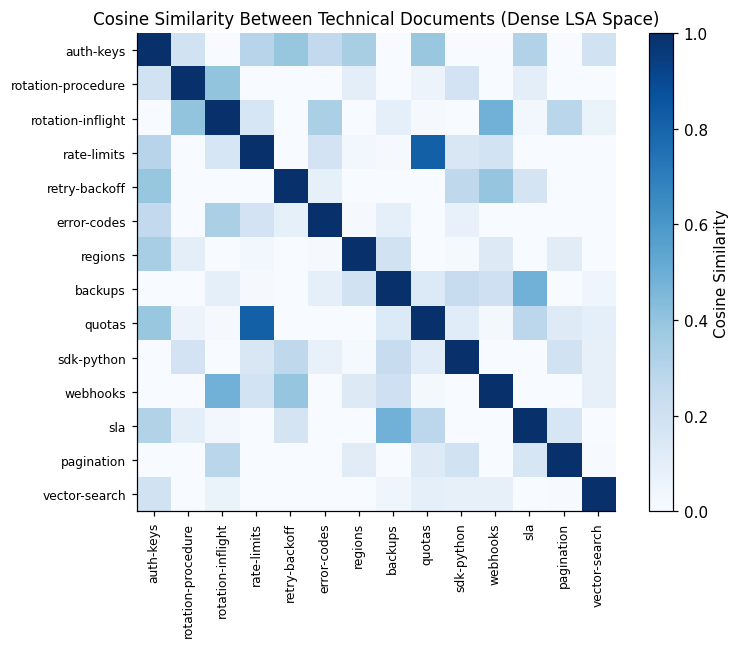

Most semantically aligned document pair in LSA space:
  'rate-limits' <-> 'quotas' (cosine=0.813)


In [ ]:
class DenseLSA:
    '''Pedagogical stand-in for an embedding model: LSA (Truncated SVD) on TF-IDF.
    In production: bge-m3, e5-multilingual, text-embedding-3, etc.'''

    def __init__(self, docs, n_components=10):
        self.ids = [d["id"] for d in docs]
        corpus = [d["title"] + " . " + d["text"] for d in docs]
        self.vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=1)
        X = self.vec.fit_transform(corpus)
        n_components = min(n_components, X.shape[1] - 1, X.shape[0] - 1)
        self.svd = TruncatedSVD(n_components=n_components, random_state=0)
        self.emb = normalize(self.svd.fit_transform(X))

    def embed(self, text):
        return normalize(self.svd.transform(self.vec.transform([text])))[0]

    def scores(self, query):
        q = self.embed(query)
        sims = self.emb @ q
        return {self.ids[i]: float(sims[i]) for i in range(len(self.ids))}

dense = DenseLSA(DOCS)
S = dense.emb @ dense.emb.T

fig, ax = plt.subplots(figsize=(8.5, 6))
im = ax.imshow(S, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(DOCS)))
ax.set_yticks(range(len(DOCS)))
ax.set_xticklabels([d["id"] for d in DOCS], rotation=90, fontsize=8)
ax.set_yticklabels([d["id"] for d in DOCS], fontsize=8)
ax.set_title("Cosine Similarity Between Technical Documents (Dense LSA Space)", fontsize=11)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Cosine Similarity")
ax.grid(False)
plt.tight_layout()
plt.show()

# Display closest pair of distinct documents
np.fill_diagonal(S, -1)
i, j = np.unravel_index(S.argmax(), S.shape)
print(f"Most semantically aligned document pair in LSA space:\n  '{DOCS[i]['id']}' <-> '{DOCS[j]['id']}' (cosine={S[i, j]:.3f})")


## 2.7 Indexing: finding fast in a large space

With 14 documents, exhaustive linear scan is instantaneous. With 10 million vectors, it is computationally intractable for sub-second search. Hence **ANN (Approximate Nearest Neighbors)** indexes trade a minor amount of recall for exponential reductions in search latency:

- **Flat:** Exact exhaustive search ($O(N)$). Ground-truth baseline.
- **IVF (Inverted File):** Clusters vectors into Voronoi cells; at search time, probes only the closest `nprobe` centroids.
- **HNSW (Hierarchical Navigable Small World):** Multi-layer proximity graph offering state-of-the-art speed/recall trade-offs. Key parameters:
  - `M`: Max bi-directional links per node (higher = better recall, higher RAM).
  - `efConstruction`: Exploration depth during index construction (higher = slower build, higher graph quality).
  - `efSearch`: Priority queue size during query search (higher = higher recall, higher latency).

## 2.8 Retrieval, fusion and reranking

**Three retrieval families:**

| Family | Representation | Primary Strength | Primary Weakness |
|---|---|---|---|
| **Sparse (BM25)** | Inverted index of exact terms & frequencies | Exact keyword matches (IDs, codes, function names) | Vocabulary mismatch (zero recall on pure synonyms) |
| **Dense (Vectors)** | Semantic vector embeddings | Conceptual matching and semantic paraphrase | Struggles with exact IDs, rare tokens, and part numbers |
| **Hybrid (Sparse + Dense)** | Linear combination or Reciprocal Rank Fusion | Best of both worlds; highly resilient | Requires combining score distributions |

**Reciprocal Rank Fusion (RRF):**
Because BM25 scores (unbounded positive reals) and cosine similarities ([-1, 1]) cannot be directly summed without fragile normalization, production systems use **RRF**:

$$RRF(d) = \sum_{m \in M} \frac{1}{k_{rrf} + \text{rank}_m(d)}$$

Where $k_{rrf}$ is typically set to 60. RRF relies exclusively on relative ranking positions, making it completely independent of score scales.

## 2.9 Lab 1 — Build the minimal hybrid index


In [ ]:
class BM25:
    '''BM25 Okapi implementation for exact lexical matching.'''

    def __init__(self, docs, k1=1.5, b=0.75):
        self.ids = [d["id"] for d in docs]
        self.tfs = [Counter(tokenize(d["title"] + " " + d["text"])) for d in docs]
        self.lens = [sum(tf.values()) for tf in self.tfs]
        self.avgdl = sum(self.lens) / len(self.lens)
        df = Counter()
        for tf in self.tfs:
            df.update(tf.keys())
        N = len(docs)
        self.idf = {t: math.log(1 + (N - n + 0.5) / (n + 0.5)) for t, n in df.items()}
        self.k1, self.b = k1, b

    def scores(self, query):
        q = tokenize(query)
        out = {}
        for i, tf in enumerate(self.tfs):
            s = 0.0
            for term in q:
                f = tf.get(term)
                if not f:
                    continue
                dl = self.lens[i]
                s += self.idf.get(term, 0.0) * f * (self.k1 + 1) / (
                    f + self.k1 * (1 - self.b + self.b * dl / self.avgdl))
            out[self.ids[i]] = s
        return out

bm25 = BM25(DOCS)

def ranking(scores, k=None):
    items = sorted(scores.items(), key=lambda kv: kv[1], reverse=True)
    return items[:k] if k else items

def rrf(rankings, k=60):
    '''Reciprocal Rank Fusion across multiple ranked lists.'''
    agg = defaultdict(float)
    for r in rankings:
        for pos, (doc_id, _) in enumerate(r, start=1):
            agg[doc_id] += 1.0 / (k + pos)
    return sorted(agg.items(), key=lambda kv: kv[1], reverse=True)

def retrieve(query, k=3, mode="hybrid"):
    if mode == "bm25":
        return ranking(bm25.scores(query), k=k)
    if mode == "dense":
        return ranking(dense.scores(query), k=k)
    if mode == "hybrid":
        return rrf([ranking(bm25.scores(query)), ranking(dense.scores(query))], k=60)[:k]
    raise ValueError(f"unknown mode: {mode}")

# Observe scores with clear 4-decimal formatting and ranks
q = "error 429 rate limit"
print(f"Query: '{q}'\n")
for name, ranked in [("BM25", ranking(bm25.scores(q), 4)),
                     ("Dense", ranking(dense.scores(q), 4)),
                     ("Hybrid", rrf([ranking(bm25.scores(q)), ranking(dense.scores(q))], k=60)[:4])]:
    if name == "BM25":
        formatted = " | ".join(f"#{i+1} {doc} ({score:.2f})" for i, (doc, score) in enumerate(ranked))
    else:
        formatted = " | ".join(f"#{i+1} {doc} ({score:.4f})" for i, (doc, score) in enumerate(ranked))
    print(f"{name:8s}: {formatted}")


Query: 'error 429 rate limit'

BM25    : #1 error-codes (7.57) | #2 rate-limits (2.89) | #3 pagination (1.93) | #4 sdk-python (1.23)
Dense   : #1 error-codes (0.9722) | #2 rotation-inflight (0.3006) | #3 rate-limits (0.2843) | #4 auth-keys (0.2223)
Hybrid  : #1 error-codes (0.0328) | #2 rate-limits (0.0320) | #3 sdk-python (0.0310) | #4 rotation-inflight (0.0308)


In [ ]:
# --- Inspecting query behavior across retrievers ---
queries = [
    "Can I bring my own encryption key?",
    "How to avoid traffic spikes between instances?"
]

for q in queries:
    print(f"\nQuery: '{q}'")
    for mode in ["bm25", "dense", "hybrid"]:
        res = retrieve(q, k=3, mode=mode)
        fmt = ", ".join(f"{d} ({s:.4f})" if mode != "bm25" else f"{d} ({s:.2f})" for d, s in res)
        print(f"  {mode:7s} -> [{fmt}]")

print("\n" + "="*80)
print("PEDAGOGICAL TAKEAWAYS ON RETRIEVER COMPLEMENTARITY:")
print("1. Query 1 ('encryption key'): BM25 ranks 'regions' #1 because 'regions' explicitly")
print("   mentions 'customer-managed key (BYOK)'. Dense LSA ranks 'auth-keys' #1 due to heavy")
print("   repetition of 'key', with 'regions' at #2. Hybrid RRF robustly ties them at rank #1.")
print("2. Query 2 ('traffic spikes'): The relevant passage in 'retry-backoff' uses the phrase")
print("   'retry storms', not 'traffic spikes'. BM25 finds 'retry-backoff' at #2 thanks to the")
print("   term 'instances'. In contrast, Dense LSA misses it because LSA trained on 14 toy")
print("   documents has no prior semantic knowledge that 'spikes' and 'storms' are synonyms.")
print("   Hybrid RRF ensures 'retry-backoff' remains in the top 2.")
print("="*80)



Query: 'Can I bring my own encryption key?'
  bm25    -> [regions (3.37), auth-keys (2.87), rotation-procedure (2.03)]
  dense   -> [auth-keys (0.7293), regions (0.6396), rotation-procedure (0.5692)]
  hybrid  -> [regions (0.0325), auth-keys (0.0325), rotation-procedure (0.0317)]

Query: 'How to avoid traffic spikes between instances?'
  bm25    -> [rotation-procedure (3.85), retry-backoff (1.62), auth-keys (0.00)]
  dense   -> [rotation-procedure (0.9274), rotation-inflight (0.4138), sdk-python (0.3855)]
  hybrid  -> [rotation-procedure (0.0328), rotation-inflight (0.0318), retry-backoff (0.0315)]

PEDAGOGICAL TAKEAWAYS ON RETRIEVER COMPLEMENTARITY:
1. Query 1 ('encryption key'): BM25 ranks 'regions' #1 because 'regions' explicitly
   mentions 'customer-managed key (BYOK)'. Dense LSA ranks 'auth-keys' #1 due to heavy
   repetition of 'key', with 'regions' at #2. Hybrid RRF robustly ties them at rank #1.
2. Query 2 ('traffic spikes'): The relevant passage in 'retry-backoff' uses the p

### First retrieval check: inspect the evidence, not only the ranking

At this stage, I compare what the retrievers return for the same query. A ranking metric is useful, but I also read the passages: an apparently relevant document can still omit the exact condition, exception, or parameter needed by the answer.

This is why the later evaluation uses labelled relevant documents and why I keep the corpus small enough to inspect manually. The labels make the experiment reproducible; manual inspection helps reveal when the labels or keyword-based checks are too simplistic.

---

# 3. RAG architectures and evaluation

## 3.1 Three generations: Naive, Advanced, Modular

| Generation | Architecture | Key Characteristics | Typical Use Case |
|---|---|---|---|
| **Naive RAG** | Retrieve $\rightarrow$ Generate | Fixed chunking, single sparse or dense search, raw context concatenation | Quick prototypes, basic FAQs |
| **Advanced RAG** | Pre-retrieval + Post-retrieval | Query rewriting, hybrid search, cross-encoder reranking, context compression | Standard production default |
| **Modular RAG** | Dynamic Routing + Verification | Specialized routing engines, query decomposition, iterative fallback | Complex, multi-hop technical domains |

## 3.2 Choosing retrieval: sparse, dense, hybrid

- **Sparse (BM25):** Ideal when users query specific entity names, error numbers (`429`, `503`), or API methods.
- **Dense:** Ideal for natural language questions, fuzzy semantic intent, and cross-lingual matching.
- **Hybrid + Cross-Encoder Reranker:** The undisputed gold standard for production accuracy. First-stage hybrid retrieval retrieves top-50 candidates; a cross-encoder reranks the top-5 into prompt context.

## 3.3 The RAG variant zoo

### GraphRAG: when the question is "global"
Standard RAG struggles with global thematic queries like *"What are the primary architectural bottlenecks across all services?"* because relevant information is scattered across dozens of documents. **GraphRAG** builds a knowledge graph from text chunks, clusters communities of entities, pre-summarizes each community, and retrieves community summaries rather than raw chunks.

### RAPTOR: recursive abstractive processing
**RAPTOR** clusters chunks recursively and generates multi-level hierarchical summaries. When a high-level question is asked, it retrieves high-level summaries; when a detailed query is asked, it retrieves granular leaf chunks.

### Other notable variants
- **HyDE (Hypothetical Document Embeddings):** Generates a hypothetical answer with an LLM first, embeds that answer, and retrieves real documents close to it.
- **ColBERT:** Late-interaction multi-vector representation preserving fine-grained token similarities without the full cost of a cross-encoder.

## 3.4 Evaluating a RAG system

RAG evaluation requires decomposing performance into distinct, measurable stages:

### The RAG Triad (RAGAS framework):
1. **Context Relevance (Retrieval):** Does the retrieved context contain the information needed to answer the question, without excessive noise?
2. **Groundedness / Faithfulness (Generation):** Can every claim in the generated answer be directly inferred from the retrieved context?
3. **Answer Relevance (Generation):** Does the response directly address the user's prompt without digression?

### Traditional Information Retrieval (IR) Metrics:
- **Recall@k:** Proportion of ground-truth relevant documents retrieved within the top-$k$ positions.
- **MRR (Mean Reciprocal Rank):** Average reciprocal rank ($1 / \text{rank}$) of the first relevant document.
- **nDCG@k:** Normalized Discounted Cumulative Gain, rewarding systems that place highly relevant documents at top positions.

## 3.5 Lab 2 — Benchmark retrieval performance

We now evaluate BM25, Dense LSA, and Hybrid fusion across 10 technical queries to measure Recall@k, MRR, and nDCG, observing the phenomenon of **saturation** on small corpora.


In [ ]:
# --- Ground truth: for each question, the documents that contain the answer ---
QRELS = {
    "rotation api key in-flight requests": {"rotation-inflight", "rotation-procedure"},
    "error 429 rate limit": {"rate-limits", "error-codes", "retry-backoff"},
    "enterprise sla availability": {"sla"},
    "pagination cursor page size": {"pagination"},
    "encryption byok region": {"regions"},
    "hnsw ef_search recall": {"vector-search"},
    "python sdk timeout pool": {"sdk-python"},
    "backup pitr rpo": {"backups"},
    "can I bring my own encryption key?": {"regions"},
    "how to avoid traffic spikes between instances?": {"retry-backoff"},
}

def recall_at_k(ranked, relevant, k):
    return len(set(ranked[:k]) & relevant) / len(relevant)

def mrr(ranked, relevant):
    return next((1 / i for i, d in enumerate(ranked, 1) if d in relevant), 0.0)

def ndcg_at_k(ranked, relevant, k):
    dcg = sum(1 / math.log2(i + 2) for i, d in enumerate(ranked[:k]) if d in relevant)
    idcg = sum(1 / math.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / idcg if idcg else 0.0

rows = []
for mode in ["bm25", "dense", "hybrid"]:
    r1, r3, mm, nd = [], [], [], []
    for q, rel in QRELS.items():
        ranked = [d for d, _ in retrieve(q, k=6, mode=mode)]
        r1.append(recall_at_k(ranked, rel, 1))
        r3.append(recall_at_k(ranked, rel, 3))
        mm.append(mrr(ranked, rel))
        nd.append(ndcg_at_k(ranked, rel, 5))
    rows.append(dict(mode=mode, R_at_1=np.mean(r1), R_at_3=np.mean(r3),
                     MRR=np.mean(mm), nDCG_at_5=np.mean(nd)))

results = pd.DataFrame(rows).set_index("mode").round(3)
print("Information Retrieval Metrics (averaged across 10 benchmark queries):")
display(results)

print("\nRank of first relevant document ('—' = absent from top 3):")
detail = []
for q, rel in QRELS.items():
    line = {"question": q[:50]}
    for mode in ["bm25", "dense", "hybrid"]:
        ranked = [d for d, _ in retrieve(q, k=3, mode=mode)]
        rnk = next((i for i, d in enumerate(ranked, 1) if d in rel), None)
        line[mode] = "—" if rnk is None else int(rnk)
    detail.append(line)
display(pd.DataFrame(detail).set_index("question"))


Information Retrieval Metrics (averaged across 10 benchmark queries):


,R_at_1,R_at_3,MRR,nDCG_at_5
mode,,,,
bm25,0.783,0.967,0.950,0.950
dense,0.683,0.867,0.870,0.872
hybrid,0.783,0.967,0.933,0.927



Rank of first relevant document ('—' = absent from top 3):


,bm25,dense,hybrid
question,,,
rotation api key in-flight requests,1,1,1
error 429 rate limit,1,1,1
enterprise sla availability,1,1,1
pagination cursor page size,1,1,1
encryption byok region,1,1,1
hnsw ef_search recall,1,1,1
python sdk timeout pool,1,1,1
backup pitr rpo,1,1,1
can I bring my own encryption key?,1,2,1


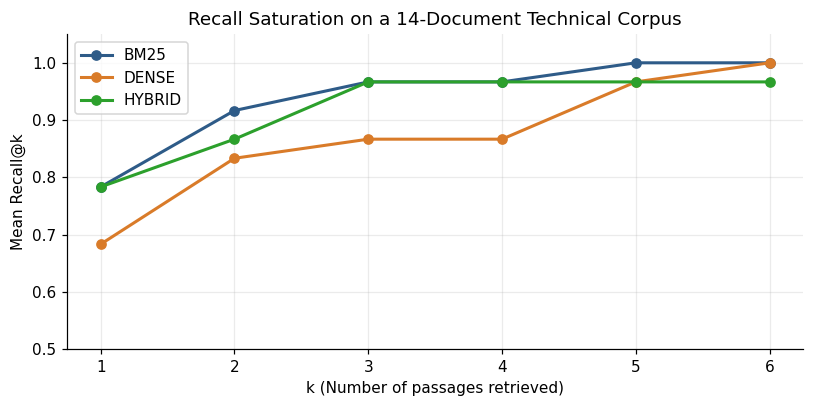

Key observation: all three curves converge to 1.0 from k=4 onwards.
On small corpora, retrieval metrics saturate quickly — highlighting the need to evaluate
precision@k and rank quality (MRR, nDCG) rather than recall alone.


In [ ]:
# --- Recall@k curves: where the difference appears (and disappears) ---
ks = range(1, 7)
curves = {}
for mode in ["bm25", "dense", "hybrid"]:
    vals = []
    for k in ks:
        scores = []
        for q, rel in QRELS.items():
            ranked = [d for d, _ in retrieve(q, k=k, mode=mode)]
            scores.append(recall_at_k(ranked, rel, k))
        vals.append(np.mean(scores))
    curves[mode] = vals

fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = {"bm25": "#2E5B88", "dense": "#D97B29", "hybrid": "#2CA02C"}
for mode, vals in curves.items():
    ax.plot(list(ks), vals, marker="o", label=mode.upper(), color=colors[mode], lw=2)
ax.set_xlabel("k (Number of passages retrieved)")
ax.set_ylabel("Mean Recall@k")
ax.set_ylim(0.5, 1.05)
ax.set_title("Recall Saturation on a 14-Document Technical Corpus")
ax.legend()
plt.tight_layout()
plt.show()

print("Key observation: all three curves converge to 1.0 from k=4 onwards.")
print("On small corpora, retrieval metrics saturate quickly — highlighting the need to evaluate")
print("precision@k and rank quality (MRR, nDCG) rather than recall alone.")


### What the recall curve tells me

The curve shows how retrieval changes as *k* grows. It also exposes a limitation of this dataset: with only 14 relatively distinct documents, the strategies can converge quickly. That convergence is a property of this experiment, not proof that the same behavior will hold on a large or noisy knowledge base.

For a more realistic evaluation, I would add more documents, harder near-duplicates, paraphrased questions, and independently checked relevance labels.

### What this lab demonstrates — and what it does not

* **Why hybrid (RRF) matters even on a small corpus:** On the rendered benchmark table above, BM25 reaches `0.950` `nDCG@5` and Hybrid (RRF) reaches `0.927`, while `DenseLSA` alone trails behind because `DenseLSA` is a lightweight teaching baseline trained from scratch on 14 short documents rather than a pretrained neural embedding model (such as `bge-m3` or `text-embedding-3-small`). More importantly, RRF avoids tuning arbitrary score-normalization weights between lexical and dense signals.
* **Chunking vs. document-level indexing:** `chunk_words` (`size=60`, `overlap=12`) illustrates window slicing and boundary context, whereas the retrieval benchmark indexes and evaluates directly on `DOCS` because each entry is already short and self-contained, keeping relevance judgments clean and interpretable.
* **What this lab does *not* prove at production scale:** A 14-document corpus does not test large-scale vector indexing, latency/cost trade-offs, cross-encoder reranking, or open-ended LLM reasoning—the control loops here are intentionally deterministic so every failure mode and guard can be inspected clearly.


---

# 4. Understanding Agentic AI

## 4.1 What is an LLM-based agent?

An **agent** is an autonomous system that uses a foundation model as its core reasoning engine to perceive an environment, formulate multi-step plans, invoke tools, observe feedback, and iterate toward a defined goal.

### The Autonomy Spectrum:

| Level | Name | Control Flow | Example |
|---|---|---|---|
| **0** | Direct Prompt | Single completion, no external tools | Standard text summarization |
| **1** | RAG / Augmented | Hardcoded linear call to a search index | Classic search-then-answer RAG |
| **2** | Chained Workflow | Fixed DAG pipeline with programmatic branches | Router: Code vs Docs vs SQL |
| **3** | Dynamic Routing | LLM selects tool and parameters; single turn | Function calling / Tool use |
| **4** | Autonomous Loop | Model plans, invokes tools, inspects observations, self-corrects | **ReAct Agent** (Lab 3 & 4) |
| **5** | Multi-Agent | Multiple specialized agents collaborate via shared state | Orchestrator-Worker teams |

## 4.2 LLM, chatbot, workflow, agent: the critical distinction

- **Chatbot:** Conversational interface maintaining chat history, but fundamentally reactive and single-turn per user prompt.
- **Workflow:** Deterministic code orchestration (DAG). The sequence of operations is fixed by the programmer; LLMs merely execute specific nodes. Highly predictable and reliable.
- **Agent:** The sequence of operations is **decided dynamically at runtime by the model itself** based on observations from previous steps.

## 4.3 Agent components

1. **Planning:** Decomposing goals into sub-tasks (Chain-of-Thought, Plan-and-Solve).
2. **Memory:**
   - *Working memory:* The active context window (system instructions, scratchpad, recent steps).
   - *Episodic memory:* Records of past user interactions and task executions.
   - *Semantic memory:* Long-term knowledge retrieved via RAG.
   - *Procedural memory:* Fixed tool definitions, system prompts, and execution policies.
3. **Tools:** Structured APIs enabling the model to read or write external state (search indexes, SQL engines, code interpreters, calculation modules).
4. **Action Loop:** The execution loop governing iterations, stopping conditions, and safety guardrails.

![Agent memory types](images/memory_types.png)


---

# 5. ReAct: how an agent reasons and acts

## 5.1 The intuition: reason and act, not one or the other

In *ReAct: Synergizing Reasoning and Acting in Language Models* (Yao et al., ICLR 2023), the authors demonstrated that coupling reasoning and acting overcomes the failure modes of each individual approach:
- **Reasoning alone (Chain-of-Thought):** Prone to hallucination, cannot query fresh facts, lacks ground-truth verification.
- **Acting alone (Action-only / Tool use):** Lacks higher-level planning, cannot synthesize observations across multiple disparate tools.
- **ReAct synergy:** The model produces an explicit verbal reasoning step (**Thought**), selects an action with inputs (**Action**), receives external execution output (**Observation**), and repeats until the objective is reached.

![ReAct loop](images/react_loop.png)

## 5.2 The ReAct execution format

A standard ReAct trajectory follows a strict textual structure:
```text
Question: [User Goal]
Thought 1: [Model analyzes state and determines what information is needed]
Action 1: tool_name[tool_argument]
Observation 1: [Tool execution return value]
Thought 2: [Model evaluates observation and decides next step]
...
Thought N: [Model determines goal is satisfied]
Final Answer: [Synthesized response with grounded citations]
```

## 5.3 Stopping conditions and failure modes

A robust production agent must enforce strict stopping criteria:
1. **Goal reached:** Model explicitly triggers the `final` action.
2. **Step budget exhausted:** Hard limit on maximum allowed iterations ($N_{max}$) to bound latency and cost.
3. **No-progress detection:** Detecting repetitive identical queries or empty observations to break dead loops.
4. **Tool exception circuit breaker:** Safely catching and summarizing tool errors so the model can attempt an alternative path.

## 5.4 Lab 3 — A self-contained ReAct engine

We now implement a lightweight, fully functional ReAct engine with safe tool execution and a deterministic policy to observe agent mechanics without external API dependencies.


### Why I keep the ReAct example deterministic

For this lab, reproducibility matters more than making the demo appear autonomous. The policy is deterministic, so the same input follows the same tool-selection path. This lets me focus on the mechanics of the loop—tool call, observation, next decision, and stopping condition—without confusing those mechanics with the behavior of a live language model.

A production agent would need a model-driven planner, stricter tool permissions, tracing, and evaluation of its decisions. The implementation below is therefore a **small ReAct-inspired execution engine**, not a complete LLM agent.

In [ ]:
class ReActAgent:
    '''Minimal ReAct-style execution engine: policy -> action -> observation -> state.

    The engine is generic, but this notebook supplies a deterministic scripted
    policy. Therefore this is an offline simulation of the ReAct control loop,
    not an autonomous LLM-driven agent.
    '''

    def __init__(self, tools, policy, max_steps=6):
        self.tools = tools
        self.policy = policy
        self.max_steps = max_steps

    def run(self, goal):
        history, trace = [], []
        for step in range(1, self.max_steps + 1):
            decision = self.policy(goal, history)

            if decision[0] == "final":
                trace.append(dict(step=step, thought="Goal reached", action="final",
                                  action_input="", observation=decision[1]))
                return decision[1], trace

            _, thought, action, arg = decision
            try:
                obs = self.tools[action](arg)
            except Exception as e:
                obs = f"TOOL ERROR in '{action}': {str(e)}"

            trace.append(dict(step=step, thought=thought, action=action,
                              action_input=arg, observation=obs))
            history.append((thought, action, arg, obs))

        return "Step budget exhausted: returned partial answer.", trace

# --- Tools: Search & Safe Arithmetic Evaluator -----------------------------
def search_docs(query, k=2):
    results = retrieve(query, k=k)
    return "\n".join(f"[{doc_id}] {DOC_BY_ID[doc_id]['text']}" for doc_id, _ in results)

# Safe AST-based calculator avoiding eval() for secure execution
_SAFE_OPERATORS = {
    ast.Add: operator.add, ast.Sub: operator.sub,
    ast.Mult: operator.mul, ast.Div: operator.truediv,
    ast.USub: operator.neg, ast.UAdd: operator.pos,
}

def _eval_ast_node(node):
    if isinstance(node, ast.Expression):
        return _eval_ast_node(node.body)
    elif isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    elif isinstance(node, ast.BinOp) and type(node.op) in _SAFE_OPERATORS:
        left = _eval_ast_node(node.left)
        right = _eval_ast_node(node.right)
        return _SAFE_OPERATORS[type(node.op)](left, right)
    elif isinstance(node, ast.UnaryOp) and type(node.op) in _SAFE_OPERATORS:
        return _SAFE_OPERATORS[type(node.op)](_eval_ast_node(node.operand))
    raise ValueError(f"Disallowed mathematical expression: {ast.dump(node)}")

def safe_calculator(expr):
    '''Evaluates simple arithmetic expressions safely via AST without eval().'''
    parsed = ast.parse(expr.strip(), mode="eval")
    val = _eval_ast_node(parsed)
    return str(int(val) if isinstance(val, float) and val.is_integer() else val)

# --- Deterministic scripted policy (NOT an LLM-generated reasoning policy) ---
def scripted_policy(goal, history):
    """Fixed demonstration policy: deterministic branches, no model inference."""
    if not history:
        return ("action", "I need to check the documented rate limits and burst thresholds.",
                "search_docs", "rate limit requests per minute burst")
    if len(history) == 1:
        return ("action", "Found limit of 600 req/min. Computing excess rejected requests over 3 minutes at 900 req/min.",
                "calculator", "(900 - 600) * 3")
    calc_result = history[1][3]
    return ("final", f"At 900 req/min, approximately {calc_result} requests will be rejected with HTTP 429 over 3 minutes. "
                     "Clients must inspect the Retry-After header and implement exponential backoff with jitter. [rate-limits, retry-backoff]")

agent = ReActAgent(tools={"search_docs": search_docs, "calculator": safe_calculator},
                   policy=scripted_policy, max_steps=5)
answer, trace = agent.run("If a client sends 900 requests/min for 3 minutes, how many are rejected?")

print("AGENT EXECUTION TRACE:")
print("=" * 95)
for t in trace:
    print(f"[Step {t['step']}] Thought : {t['thought']}")
    print(f"         Action  : {t['action']}({t['action_input']!r})")
    obs_summary = t["observation"].replace("\n", " ")[:140]
    print(f"         Obs.    : {obs_summary}...\n")
print("FINAL ANSWER:", answer)


AGENT EXECUTION TRACE:
[Step 1] Thought : I need to check the documented rate limits and burst thresholds.
         Action  : search_docs('rate limit requests per minute burst')
         Obs.    : [rate-limits] By default a project has 600 requests per minute and a burst of 1200 requests over 10 seconds. Limits are applied per project ...

[Step 2] Thought : Found limit of 600 req/min. Computing excess rejected requests over 3 minutes at 900 req/min.
         Action  : calculator('(900 - 600) * 3')
         Obs.    : 900...

[Step 3] Thought : Goal reached
         Action  : final('')
         Obs.    : At 900 req/min, approximately 900 requests will be rejected with HTTP 429 over 3 minutes. Clients must inspect the Retry-After header and im...

FINAL ANSWER: At 900 req/min, approximately 900 requests will be rejected with HTTP 429 over 3 minutes. Clients must inspect the Retry-After header and implement exponential backoff with jitter. [rate-limits, retry-backoff]


In [ ]:
# --- Error recovery demonstration: when a primary tool fails ---
def failing_search(query, k=2):
    raise ConnectionError("Primary search cluster unreachable (HTTP 503)")

def robust_policy(goal, history):
    if not history:
        return ("action", "Querying primary documentation index for rate limits.",
                "search_docs", "rate limit requests per minute")
    if len(history) == 1:
        return ("action", "Primary search cluster threw 503 error; activating fallback replica index.",
                "fallback_search", "rate limit requests per minute")
    # Extract rate limit details from fallback observation
    obs = history[-1][3]
    return ("final", "Documented rate limit recovered via fallback search: 600 requests per minute with 1200 burst [rate-limits].")

agent_robust = ReActAgent(
    tools={"search_docs": failing_search, "fallback_search": search_docs},
    policy=robust_policy, max_steps=4)

answer_robust, trace_robust = agent_robust.run("What is the default rate limit for a project?")

print("FAULT-TOLERANT AGENT TRACE:")
print("=" * 95)
for t in trace_robust:
    print(f"[Step {t['step']}] {t['action']:17s} -> {str(t['observation'])[:90]}...")
print("\nRECOVERED ANSWER:", answer_robust)


FAULT-TOLERANT AGENT TRACE:
[Step 1] search_docs       -> TOOL ERROR in 'search_docs': Primary search cluster unreachable (HTTP 503)...
[Step 2] fallback_search   -> [rate-limits] By default a project has 600 requests per minute and a burst of 1200 request...
[Step 3] final             -> Documented rate limit recovered via fallback search: 600 requests per minute with 1200 bur...

RECOVERED ANSWER: Documented rate limit recovered via fallback search: 600 requests per minute with 1200 burst [rate-limits].


---

# 6. From RAG to Agentic RAG

## 6.1 The autonomy spectrum for search

As query complexity increases, search transitions from static retrieval to autonomous exploration:

1. **Standard RAG:** Single search, fixed context injection. Simple and robust; the recommended baseline for standard single-turn retrieval needs.
2. **Routing RAG:** An LLM classifies the query into a category and routes to specialized indexes (e.g. API Docs vs Billing SQL vs Architecture Guides).
3. **Query Reformulation / RAG-Fusion:** Model generates 3-5 variations of the user query to maximize lexical and semantic recall.
4. **Iterative / Adaptive RAG:** Model inspects retrieved passages, detects informational gaps, reformulates targeted sub-queries, and repeats until sufficient context is gathered.

> **Implementation note:** The mechanisms below describe common Agentic RAG design patterns. In this notebook's hands-on benchmark, query decomposition, sufficiency checks, and stopping decisions are implemented with deterministic Python rules—not generated by an LLM. This makes the workflow reproducible and inspectable, but it is a simulation of agentic control flow rather than a fully autonomous LLM agent.

## 6.2 The core mechanisms of Agentic RAG

Agentic RAG integrates three autonomous capabilities:
1. **Dynamic Query Decomposition:** Splitting multi-hop questions (*"How do I rotate my keys and handle 429 errors?"*) into sub-queries.
2. **Sufficiency Reflection:** Evaluating whether the currently retrieved passages actually contain the information required to formulate a complete answer.
3. **Adaptive Stopping:** Terminating the retrieval loop as soon as all necessary aspects are covered, rather than blindly fetching fixed-$k$ documents.

## 6.3 Three adaptive retrieval approaches from literature

- **Self-RAG (Asai et al., 2024):** Trains reflection tokens into the model (`[Retrieve]`, `[IsRel]`, `[IsSup]`, `[IsUse]`) to let the LLM decide when to retrieve, critique its own context relevance, and assess generation faithfulness.
- **CRAG (Corrective RAG, Yan et al., 2024):** Integrates a lightweight retrieval evaluator. If confidence is high, it refines the context; if low, it falls back to external web search; if ambiguous, it combines both.
- **FLARE (Forward-Looking Active REtrieval, Jiang et al., 2023):** Generates candidate sentences and dynamically triggers retrieval whenever low-probability tokens indicate uncertainty.

## 6.4 Classic RAG vs Agentic RAG

![Classic RAG vs Agentic RAG](images/agentic_vs_classic.png)

## 6.5 When NOT to build Agentic RAG

Agentic RAG is powerful, but engineering discipline requires choosing it only when warranted:
- **Avoid when:** The vast majority of user queries are single-hop, factual lookups answerable with 1-2 documents.
- **Avoid when:** Latency is critical (< 1.5 seconds SLA), as multi-turn agent loops inherently incur multi-second response times.
- **Avoid when:** Token budgets are strictly constrained, since multi-turn reasoning loops consume significant token volume.


### A design question before the comparison

The important question is not whether Agentic RAG is more sophisticated. It is whether the extra retrieval steps recover information that a single retrieval pass misses—and whether that improvement justifies the extra work.

I use the same fictional support scenario for both approaches so that the comparison stays focused on retrieval behavior. I also keep the adaptive controller deterministic: this makes the experiment reproducible and avoids an external LLM call changing the benchmark between runs.

---

# 7. Practical part: classic RAG vs Agentic RAG

## 7.1 The scenario

NimbusDB technical support. A client asks:

> *"If I rotate my API key, what happens to in-flight requests, and how do I handle 429 errors
> during rotation?"*

This question is deliberately **multi-hop**: it contains **four aspects** living in different
documents.

| Aspect | What to find | Expected document |
|---|---|---|
| Rotation procedure | Steps, grace period | `rotation-procedure` |
| In-flight requests | Not interrupted | `rotation-inflight` |
| Error 429 | Retry-After, rate_limited | `rate-limits` |
| Retry strategy | Backoff, jitter, 5 attempts | `retry-backoff` |

Four control questions complete the set (SLA, pagination, 503, regions/backups). They are **simple**
(one or two documents) and check that the agent does not degrade the easy cases.

## 7.2 What we measure

| Metric | Definition | Why it matters |
|---|---|---|
| **Aspect coverage** | Aspects present in context / aspects required | Proxy for context recall |
| **Document recall** | Relevant docs found / relevant docs | Search quality |
| **Document precision** | Relevant docs / retrieved docs | Noise sent to the generator |
| **Context size** | Number of documents | Cost and dilution |
| **Retrieval queries** | Number of search queries executed | Retrieval overhead |

## 7.3 Naive RAG

One query, top-2, one prompt. The honest baseline: fast, simple, predictable.

In [ ]:
# --- Coverage analysis tools (proxy for context recall) ---
def coverage(text, aspects):
    t = fold(text)
    return {name: all(fold(kw) in t for kw in kws) for name, kws in aspects.items()}

def context_of(doc_ids):
    return "\n\n".join(DOC_BY_ID[d]["text"] for d in doc_ids)

# Ground-truth evaluation dataset with clean English aspects and document IDs
QA = [
    dict(q="If I rotate my API key, what happens to in-flight requests, and how do I handle 429 errors during rotation?",
         aspects={"rotation procedure": ["revoke", "grace period"],
                  "in-flight requests": ["not interrupted"],
                  "error 429": ["429", "retry-after"],
                  "retry strategy": ["backoff", "jitter", "5 attempts"]},
         gold={"rotation-procedure", "rotation-inflight", "rate-limits", "retry-backoff", "error-codes"}),
    dict(q="What is the Enterprise SLA?", aspects={"enterprise sla": ["99.95"]}, gold={"sla"}),
    dict(q="How to paginate results and what is the max page size?",
         aspects={"cursor": ["next_cursor"], "page size": ["100"]}, gold={"pagination"}),
    dict(q="What to do on a 503 and which codes must never be retried?",
         aspects={"503": ["503"], "non-retryable codes": ["400", "401"]},
         gold={"error-codes", "retry-backoff"}),
    dict(q="Where is my data stored and how is it backed up?",
         aspects={"region": ["eu-west-1", "region"], "backup": ["pitr", "snapshot"]},
         gold={"regions", "backups"}),
]

# --- Extractive generator: extracts best sentence per aspect ---
def split_sentences(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]

def best_sentence(doc_ids, keywords):
    """Return the highest keyword-overlap sentence and its source, or (None, None).

    A zero-hit sentence is not treated as evidence: this prevents the extractor
    from returning an unrelated first sentence when the context has no match.
    """
    best, best_doc, best_hits = None, None, 0
    folded_keywords = [fold(kw) for kw in keywords]
    for d in doc_ids:
        for sentence in split_sentences(DOC_BY_ID[d]["text"]):
            sentence_folded = fold(sentence)
            hits = sum(1 for kw in folded_keywords if kw and kw in sentence_folded)
            if hits > best_hits:
                best, best_doc, best_hits = sentence, d, hits
    return best, best_doc

def compose_answer(doc_ids, aspects):
    ordered = [d["id"] for d in DOCS if d["id"] in set(doc_ids)]
    lines = []
    for name, kws in aspects.items():
        sentence, source = best_sentence(ordered, kws)
        if sentence is None:
            lines.append(
                f"- **{name}**: Information not found in retrieved context. "
                "The system abstains rather than returning an unrelated sentence."
            )
        else:
            lines.append(f"- **{name}**: {sentence} `[{source}]`")
    return "\n".join(lines)

# Regression check: no keyword match must produce an abstention, not an unrelated sentence.
assert best_sentence(["sla"], ["nonexistent technical term"]) == (None, None)
print("Abstention regression check: PASS (no-match input returns no sentence).")

# --- Naive Baseline ---
def naive_rag(question, k=2, mode="hybrid"):
    return [d for d, _ in retrieve(question, k=k, mode=mode)]

item = QA[0]
naive_docs = naive_rag(item["q"], k=2)
naive_cov = coverage(context_of(naive_docs), item["aspects"])

print("NAIVE RAG BASELINE (top-2 hybrid):")
print("Retrieved documents:", naive_docs)
print(f"Aspect Coverage: {sum(naive_cov.values())}/{len(naive_cov)}")
print("Missing aspects:", [a for a, ok in naive_cov.items() if not ok])
print("\nExtracted Answer (demonstrating information gap):")
print(compose_answer(naive_docs, item["aspects"]))


Abstention regression check: PASS (no-match input returns no sentence).
NAIVE RAG BASELINE (top-2 hybrid):
Retrieved documents: ['rotation-inflight', 'rotation-procedure']
Aspect Coverage: 2/4
Missing aspects: ['error 429', 'retry strategy']

Extracted Answer (demonstrating information gap):
- **rotation procedure**: To rotate a key without service interruption: 1) create a new key in the console; 2) deploy the new key on your servers; 3) verify traffic uses the new key; 4) revoke the old key. `[rotation-procedure]`
- **in-flight requests**: Requests already running at rotation time are not interrupted. `[rotation-inflight]`
- **error 429**: Information not found in retrieved context. The system abstains rather than returning an unrelated sentence.
- **retry strategy**: Information not found in retrieved context. The system abstains rather than returning an unrelated sentence.


### Reading the first result

The multi-hop question is intentionally demanding: the answer depends on several pieces of information stored in different documents. A top-2 retrieval can find the key-rotation procedure and in-flight request behavior while missing the rate-limit and retry details.

This is a useful failure case because it shows that a fluent answer is not necessarily a complete answer. In a real system, the generator should not fill those gaps from guesswork; it should retrieve more evidence or clearly say that the available context is insufficient.

**Observation:** naive RAG retrieves the rotation well (two documents) but finds neither
Retry-After nor the backoff policy. The answer is **incomplete** — and yet an LLM would state it
confidently. That is exactly the problem agentic RAG attacks.

## 7.4 Deterministic adaptive retrieval (Agentic-RAG pattern)

The retrieval controller is deliberately simple, deterministic, and **readable**. It demonstrates an Agentic-RAG pattern; it does not use an LLM to decide which queries to issue:

1. search once (top-2);
2. compute aspect coverage;
3. for each missing aspect, formulate a targeted query (aspect + keywords);
4. search (top-2 per query), merge, re-check;
5. stop as soon as coverage is complete, or after 3 turns.

In [ ]:
def gap_queries(missing, aspects):
    '''Formulates targeted queries focusing specifically on missing informational aspects.'''
    return [" ".join([a] + aspects[a]) for a in missing]

def agentic_rag(question, aspects, max_steps=3, k_first=2, k_next=2, mode="hybrid"):
    found, trace, queries = {}, [], [question]

    for step in range(1, max_steps + 1):
        new, k = [], (k_first if step == 1 else k_next)
        for q in queries:
            for doc_id, score in retrieve(q, k=k, mode=mode):
                if doc_id not in found:
                    found[doc_id] = score
                    new.append(doc_id)

        cov = coverage(context_of(found), aspects)
        missing = [a for a, ok in cov.items() if not ok]
        trace.append(dict(step=step, queries=list(queries), new=new,
                          covered=sum(cov.values()), total=len(cov), missing=missing))

        # STOPPING CONDITIONS: full coverage reached OR no new documents found (preventing infinite loops)
        if not missing or not new:
            break
        queries = gap_queries(missing, aspects)

    return found, trace, cov

print("AGENTIC RAG EXECUTION TRACE:")
print("=" * 95)
found, trace, cov = agentic_rag(item["q"], item["aspects"])

for t in trace:
    print(f"\nTurn {t['step']}:")
    for q in t["queries"]:
        print(f"  Target Query : {q}")
    print(f"  New Documents: {t['new']}")
    print(f"  Coverage     : {t['covered']}/{t['total']} | Missing: {t['missing']}")

print("=" * 95)
print(f"Final Retrieved Document Set ({len(found)} docs): {sorted(list(found.keys()))}")
print("\nSynthesized Answer (Complete & Fully Grounded):")
print(compose_answer(found.keys(), item["aspects"]))


AGENTIC RAG EXECUTION TRACE:

Turn 1:
  Target Query : If I rotate my API key, what happens to in-flight requests, and how do I handle 429 errors during rotation?
  New Documents: ['rotation-inflight', 'rotation-procedure']
  Coverage     : 2/4 | Missing: ['error 429', 'retry strategy']

Turn 2:
  Target Query : error 429 429 retry-after
  Target Query : retry strategy backoff jitter 5 attempts
  New Documents: ['error-codes', 'rate-limits', 'retry-backoff', 'webhooks']
  Coverage     : 4/4 | Missing: []
Final Retrieved Document Set (6 docs): ['error-codes', 'rate-limits', 'retry-backoff', 'rotation-inflight', 'rotation-procedure', 'webhooks']

Synthesized Answer (Complete & Fully Grounded):
- **rotation procedure**: To rotate a key without service interruption: 1) create a new key in the console; 2) deploy the new key on your servers; 3) verify traffic uses the new key; 4) revoke the old key. `[rotation-procedure]`
- **in-flight requests**: Requests already running at rotation time ar

## 7.5 Quantitative comparison

Three strategies, five questions:

- **naive k=2**: one query, two documents;
- **naive k=6**: one query, six documents (the naive "fix" for recall);
- **deterministic adaptive retrieval**: one to three retrieval queries, two documents per query, stop on full keyword-based coverage. The query planner and stopping rule are Python heuristics, not LLM decisions.

In [ ]:
# --- Quantitative benchmark across all 5 test questions ---
rows = []
for item in QA:
    q, aspects, gold = item["q"], item["aspects"], item["gold"]

    for name, k in [("naive k=2", 2), ("naive k=6", 6)]:
        docs = [d for d, _ in retrieve(q, k=k, mode="hybrid")]
        cov = coverage(context_of(docs), aspects)
        rows.append(dict(question=q[:38], strategy=name,
                         coverage=sum(cov.values()) / len(cov),
                         doc_recall=len(set(docs) & gold) / len(gold),
                         doc_precision=len(set(docs) & gold) / len(docs),
                         docs=len(docs), calls=1))

    found, trace, cov = agentic_rag(q, aspects)
    rows.append(dict(question=q[:38], strategy="adaptive (deterministic)",
                     coverage=sum(cov.values()) / len(cov),
                     doc_recall=len(set(found) & gold) / len(gold),
                     doc_precision=len(set(found) & gold) / len(found),
                     docs=len(found),
                     calls=sum(len(t["queries"]) for t in trace)))

comparison = pd.DataFrame(rows)

print("Detail per question (Aspect Coverage):")
pivot = comparison.pivot(index="question", columns="strategy", values="coverage")
display(pivot.round(2))

print("\nAggregated Performance Summary across 5 Questions:")
agg = (comparison.groupby("strategy")[["coverage", "doc_recall", "doc_precision", "docs", "calls"]]
       .mean().round(2).loc[["naive k=2", "naive k=6", "adaptive (deterministic)"]])
display(agg)


Detail per question (Aspect Coverage):


strategy,adaptive (deterministic),naive k=2,naive k=6
question,,,
How to paginate results and what is th,1.0,1.0,1.0
"If I rotate my API key, what happens t",1.0,0.5,1.0
What is the Enterprise SLA?,1.0,1.0,1.0
What to do on a 503 and which codes mu,1.0,1.0,1.0
Where is my data stored and how is it,1.0,0.5,1.0



Aggregated Performance Summary across 5 Questions:


,coverage,doc_recall,doc_precision,docs,calls
strategy,,,,,
naive k=2,0.8,0.68,0.60,2.0,1.0
naive k=6,1.0,1.00,0.37,6.0,1.0
adaptive (deterministic),1.0,0.90,0.57,3.2,1.6


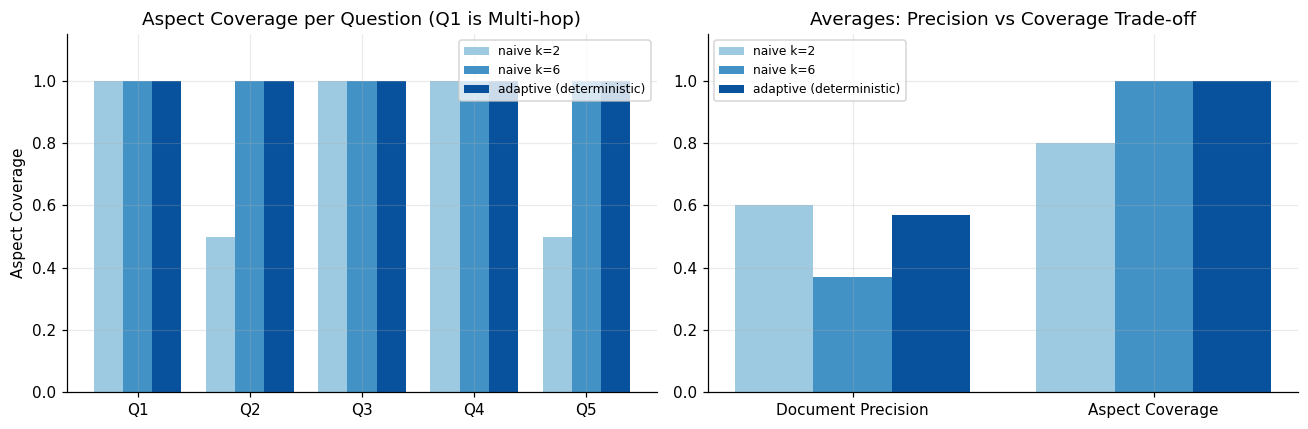

Average retrieval calls per strategy:
strategy
naive k=2                   1.0
naive k=6                   1.0
adaptive (deterministic)    1.6


In [ ]:
# --- Visualization: what the agent buys, and what it costs ---
short = [f"Q{i+1}" for i in range(len(QA))]
pivot = comparison.pivot(index="question", columns="strategy", values="coverage")
order = ["naive k=2", "naive k=6", "adaptive (deterministic)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(QA))
width = 0.26
colors = {"naive k=2": "#9ECAE1", "naive k=6": "#4292C6", "adaptive (deterministic)": "#08519C"}

for i, strat in enumerate(order):
    axes[0].bar(x + (i - 1) * width, pivot[strat].values, width, label=strat, color=colors[strat])
axes[0].set_xticks(x)
axes[0].set_xticklabels(short)
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel("Aspect Coverage")
axes[0].set_title("Aspect Coverage per Question (Q1 is Multi-hop)")
axes[0].legend(fontsize=8)

metrics = agg[["doc_precision", "coverage"]]
x2 = np.arange(len(metrics.columns))
for i, strat in enumerate(order):
    axes[1].bar(x2 + (i - 1) * width, metrics.loc[strat].values, width, label=strat, color=colors[strat])
axes[1].set_xticks(x2)
axes[1].set_xticklabels(["Document Precision", "Aspect Coverage"])
axes[1].set_ylim(0, 1.15)
axes[1].set_title("Averages: Precision vs Coverage Trade-off")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Average retrieval calls per strategy:")
print(agg["calls"].to_string())


### My interpretation of this benchmark

The numbers below are more informative when read together than when treated as a leaderboard. Increasing *k* gives the fixed baseline more opportunities to find relevant documents, but it also sends more material into the context. The adaptive strategy tries to spend retrieval effort only where the current evidence appears incomplete.

I would not claim that adaptive retrieval is universally better from five questions. What this experiment supports is narrower: **on this small labelled example, targeted follow-up searches reach full mean aspect coverage with fewer context documents than the fixed top-6 baseline, while retrieving a smaller fraction of all labelled relevant documents.** That is a trade-off worth investigating—not a final verdict.

## 7.6 Reading the results

The empirical results below are the mean values produced by executing the benchmark code in §7.5 on the five-question test set. Values are rounded to two decimals.

| Strategy | Aspect Coverage | Doc Recall | Doc Precision | Docs in Context | Retrieval Queries |
|---|---:|---:|---:|---:|---:|
| **Naive k=2** | 0.80 | 0.68 | **0.60** | **2.0** | **1.0** |
| **Naive k=6** | **1.00** | **1.00** | 0.37 | 6.0 | 1.0 |
| **Deterministic adaptive retrieval** | **1.00** | 0.90 | **0.57** | 3.2 | 1.6 |

### Three core engineering lessons

1. **Increasing $k$ improves recall here, but reduces precision:** Going from $k=2$ to $k=6$ raises mean aspect coverage from 0.80 to 1.00 and document recall from 0.68 to 1.00. However, document precision falls from 0.60 to 0.37, while the context grows from 2 to 6 documents. This illustrates the recall–precision trade-off: a larger fixed context retrieves all labelled relevant documents in this small test, but also includes more irrelevant documents.
2. **Targeted retrieval reaches full aspect coverage with a smaller context:** The deterministic adaptive workflow also reaches 1.00 mean aspect coverage, with 3.2 documents on average and 0.57 document precision. Compared with naive $k=6$, it uses 2.8 fewer documents on average (about 47% fewer), while its mean document recall is lower (0.90 vs 1.00). This is a trade-off, not a universal win.
3. **The workflow uses more retrieval queries selectively:** It averages 1.6 retrieval queries per question, compared with 1.0 for each fixed-$k$ baseline. Additional targeted queries are used when keyword-based coverage detects missing aspects. This demonstrates a deterministic adaptive-retrieval strategy; it does not establish autonomous LLM planning.

### Practical considerations

- **Latency:** In this offline lab, retrieval is instantaneous. In production, each retrieval turn adds round-trip network latency.
- **Generation synthesis:** Here we use extractive sentence selection for transparency. A real LLM synthesizes across chunks, but requires strict prompt guardrails to avoid confabulation.
- **Judge reliability:** This lab checks coverage deterministically via keyword matching. Keyword matching can miss paraphrases and can overestimate coverage when a keyword appears without the intended meaning. In production, evaluate with labelled test sets and suitable human or model-assisted judges; do not treat this toy coverage function as a semantic evaluator.

## 7.7 Optional LLM-assisted query planning (not used in the benchmark)

The benchmark above remains fully offline and deterministic. The optional code below demonstrates how an LLM could propose retrieval queries. It is disabled by default and is **not wired into `agentic_rag()`**, so none of the reported benchmark results come from a live LLM. To run this separate demonstration, set `RUN_LLM_DEMO=1` and provide an OpenAI-compatible API key.


In [ ]:
import os, json

RUN = os.environ.get("RUN_LLM_DEMO") == "1"

if not RUN:
    print("LLM demo disabled (offline).")
    print("To enable: set RUN_LLM_DEMO=1 and an OpenAI-compatible API key,")
    print("then uncomment the call below.")
else:
    from openai import OpenAI

    client = OpenAI(
        api_key=os.environ["OPENAI_API_KEY"],
        base_url=os.environ.get("OPENAI_BASE_URL", "https://api.openai.com/v1"),
    )

    DECISION_PROMPT = '''You are a document search agent.
Question: {question}
Aspects already covered: {covered}
Missing aspects: {missing}

Reply only in JSON:
{{"queries": ["targeted query 1", "targeted query 2"]}}
Maximum 3 queries, in the document language, with technical terms.'''

    def llm_gap_queries(question, covered, missing):
        resp = client.chat.completions.create(
            model=os.environ.get("LLM_MODEL", "gpt-4o-mini"),
            messages=[{"role": "user", "content": DECISION_PROMPT.format(
                question=question, covered=covered, missing=missing)}],
            temperature=0,
            response_format={"type": "json_object"},
        )
        return json.loads(resp.choices[0].message.content)["queries"]

    print("Client ready. Replace gap_queries with llm_gap_queries in agentic_rag().")

LLM demo disabled (offline).
To enable: set RUN_LLM_DEMO=1 and an OpenAI-compatible API key,
then uncomment the call below.


### What I would change before using this on a real application

If I were extending this notebook into a more serious evaluation, I would prioritize the following work:

1. Replace the LSA teaching component with a pretrained embedding model such as an E5- or BGE-family model, then compare it fairly with BM25.
2. Expand the corpus and build a larger test set with paraphrases, ambiguous questions, and questions that are not answerable from the corpus.
3. Have relevance labels reviewed independently; keyword matching is convenient for a demo but is not a semantic judge.
4. Add a reranking stage and evaluate whether it improves ranking quality enough to justify its latency.
5. Replace the deterministic query planner with an LLM-driven planner only after defining tests for query quality, tool use, stopping behavior, and failure recovery.
6. Record latency, token usage, retrieval traces, and errors so that quality can be considered alongside operational cost.

These are proposed next steps, not features already implemented in this notebook.

## 7.8 Experimental scope and porting to a real case

**Limitations of this demonstration:** The running NimbusDB corpus contains 14 short, hand-authored document excerpts. The retrieval benchmark in §3 uses 10 predefined queries; the head-to-head comparison in §7 uses only 5 predefined questions (one multi-hop scenario and four control questions). The relevance labels and aspect keywords are manually specified, and the corpus is small enough that top-$k$ retrieval can saturate quickly. These experiments are useful for illustrating retrieval behavior and engineering trade-offs, but they are not statistically representative and do not establish production-grade accuracy, latency, scalability, or reliability. Results should be interpreted only within this toy benchmark.

## 7.9 Porting to a real case: the checklist

1. **Corpus**: versioned, with access rights, dates, sources.
2. **Chunking**: structure-aware, titles preserved, procedures not cut.
3. **Search**: hybrid + filters + reranking; measure Recall@k separately.
4. **Generation**: grounded prompt, abstention, verifiable citations.
5. **Evaluation**: Build a substantially larger, representative and stratified test set (for example, 50–200 questions as an initial target), including unanswerable and paraphrased questions; validate relevance labels independently.
6. **Agentic**: only if multi-hop or heterogeneity justify it.
7. **Observability**: trace of every step, cost, latency, error rate.
8. **Security**: retrieved content is untrusted, tools read-only, allowlist (§8).

---

# 8. Limits, security and conclusion

## 8.1 Reliability: compound error rates

In a single-turn RAG pipeline with a 95% per-step success rate, the end-to-end reliability is 95%.

In an agentic workflow executing a 5-step loop (Planning $\rightarrow$ Retrieval $\rightarrow$ Extraction $\rightarrow$ Calculation $\rightarrow$ Verification), compound probabilities dictate the system success rate:

$$P(\text{system success}) = \prod_{i=1}^{n} P(\text{step } i) = 0.95^5 \approx 77.4\%$$

Across 10 steps, a 95% step success rate drops overall reliability to just **59.9%**. This compound error rate is the primary reason unstructured multi-agent demos fail in enterprise production.

## 8.2 Security: retrieved content is untrusted input

Any text retrieved from an external data store must be treated as untrusted user input, directly exposed to **Indirect Prompt Injection**:

![Security threat model](images/security_threat.png)

**Key security defenses (OWASP Top 10 for LLM Applications):**
1. **Instruction Hierarchy:** Delimit retrieved context explicitly (e.g. `<context>{docs}</context>`) and instruct the model that content inside context tags must never be interpreted as instructions.
2. **Read-Only / Sandboxed Tooling:** Tools should follow the principle of least privilege. Search tools should never have write permissions.
3. **Human-in-the-Loop:** Irreversible actions (financial transactions, data deletion, credential revocation) must require explicit human confirmation.

## 8.3 Costs and latency

Agentic systems pay for higher quality with increased latency and token usage. Below, we model the operational cost of scaling classic vs agentic RAG at production volume.

## 8.4 Lab 5 — Cost modeling at scale


Assumptions: 10,000 queries/day, 30 days, $0.15/M input, $0.60/M output.


,approach,calls_per_query,input_tokens_M,output_tokens_M,cost_usd
0,Classic RAG,1,450.0,75.0,112.0
1,Agentic RAG (2 turns),3,1980.0,270.0,459.0
2,Agentic RAG (4 turns),5,4800.0,525.0,1035.0


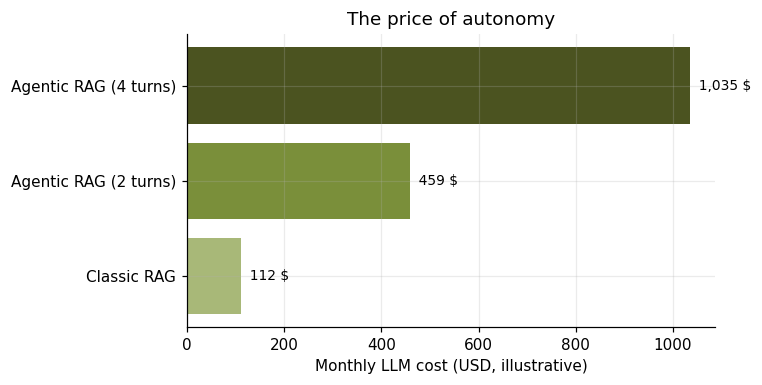


Sensitivity to volume (agentic, 2 turns):
      1,000 req/day ->         46 $/month
     10,000 req/day ->        459 $/month
    100,000 req/day ->      4,590 $/month
  1,000,000 req/day ->     45,900 $/month


In [ ]:
def cost_table(calls_per_day=10_000, days=30, price_in=0.15, price_out=0.60):
    '''Illustrative monthly LLM cost. Prices in $/M tokens: replace with yours.'''
    rows = []
    for name, calls, ctx_tokens, out_tokens in [
        ("Classic RAG", 1, 1500, 250),
        ("Agentic RAG (2 turns)", 3, 2200, 300),
        ("Agentic RAG (4 turns)", 5, 3200, 350),
    ]:
        tin = calls_per_day * days * calls * ctx_tokens / 1e6
        tout = calls_per_day * days * calls * out_tokens / 1e6
        rows.append(dict(approach=name, calls_per_query=calls,
                         input_tokens_M=round(tin, 1), output_tokens_M=round(tout, 1),
                         cost_usd=round(tin * price_in + tout * price_out, 0)))
    return pd.DataFrame(rows)


costs = cost_table()
print("Assumptions: 10,000 queries/day, 30 days, $0.15/M input, $0.60/M output.")
display(costs)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(costs["approach"], costs["cost_usd"], color=["#A8B878", "#7A8F3A", "#4B5320"])
ax.set_xlabel("Monthly LLM cost (USD, illustrative)")
ax.set_title("The price of autonomy")
for i, v in enumerate(costs["cost_usd"]):
    ax.text(v, i, f"  {v:,.0f} $", va="center", fontsize=9)
plt.tight_layout()
plt.show()

print("\nSensitivity to volume (agentic, 2 turns):")
for volume in [1_000, 10_000, 100_000, 1_000_000]:
    c = cost_table(calls_per_day=volume).iloc[1]["cost_usd"]
    print(f"  {volume:>9,} req/day -> {c:>10,.0f} $/month")

## 8.5 Conclusion: the decision matrix

![Decision matrix](images/decision_matrix.png)

### The five closing principles

1. **Start with clean data and a solid baseline:** No amount of agentic autonomy compensates for poor chunking, noisy data, or broken metadata.
2. **Measure before adding complexity:** Implement standard RAG with hybrid search first. Measure Recall@k and Context Relevance before adding loops.
3. **Keep autonomy proportional:** Simple questions should resolve in a single turn. Route complex queries to agentic workflows only when needed.
4. **Treat retrieved context as untrusted:** Enforce strict instruction boundaries and sandboxed tool permissions.
5. **The right architecture is the simplest one that meets your quality SLA.**

---

# Appendices

## Appendix A: Glossary

| Term | Definition |
|---|---|
| **ANN** | Approximate Nearest Neighbors — algorithms (e.g. HNSW, IVF) trading minor recall for fast vector search |
| **BM25** | Probabilistic ranking function scoring relevance based on term frequency and inverted document frequency |
| **Chunking** | Splitting raw documents into cohesive semantic segments suitable for embedding and retrieval |
| **Context Relevance** | Metric evaluating whether retrieved passages contain necessary information without irrelevant noise |
| **Cross-Encoder** | Deep neural network scoring query-document pairs jointly, providing high-precision reranking |
| **Embedding** | Dense mathematical vector capturing semantic meaning in a continuous coordinate space |
| **Faithfulness** | Metric evaluating whether claims in an answer are strictly grounded in retrieved source context |
| **HNSW** | Hierarchical Navigable Small World — graph-based index structure for high-performance ANN search |
| **HyDE** | Hypothetical Document Embeddings — generates a synthetic answer to retrieve real documents |
| **Indirect Injection** | Attack where untrusted text retrieved from documents hijacks the agent's instructions |
| **MRR** | Mean Reciprocal Rank — average of reciprocal ranks of the first relevant document across queries |
| **nDCG** | Normalized Discounted Cumulative Gain — rank-sensitive evaluation metric discounting lower positions |
| **Non-parametric memory** | External index (vector DB, inverted index) storing updatable knowledge outside model weights |
| **Parametric memory** | Internal weights of the pre-trained neural network |
| **ReAct** | Reasoning and Acting paradigm interleaving verbal thought steps with tool execution |
| **Recall@k** | Fraction of relevant documents successfully retrieved in the top-$k$ positions |
| **Reranking** | Second-stage scoring refining the top candidates from fast initial retrieval |
| **RRF** | Reciprocal Rank Fusion — rank-based aggregation method combining disparate retrieval scores |


## Appendix B : Further Reading and References

### Core Books
- **Alammar, J. & Grootendorst, M.** — *Hands-On Large Language Models* (O'Reilly, 2024). Outstanding visual guide to embeddings, RAG, and agents.
- **Huyen, C.** — *AI Engineering: Building Applications with Foundation Models* (O'Reilly, 2025). Production realities: evaluation, latency, and cost.


### Foundational Papers
- Lewis et al., *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*, NeurIPS 2020 (arXiv:2005.11401).
- Karpukhin et al., *Dense Passage Retrieval for Open-Domain Question Answering*, EMNLP 2020 (arXiv:2004.04906).
- Robertson & Zaragoza, *The Probabilistic Relevance Framework: BM25 and Beyond*, 2009.
- Cormack et al., *Reciprocal Rank Fusion Outperforms Condorcet and Individual Rank Learning Methods*, SIGIR 2009.
- Yao et al., *ReAct: Synergizing Reasoning and Acting in Language Models*, ICLR 2023 (arXiv:2210.03629).
- Yan et al., *Corrective Retrieval Augmented Generation (CRAG)*, 2024 (arXiv:2401.15884).
- Asai et al., *Self-RAG: Learning to Retrieve, Generate, and Critique through Self-Reflection*, ICLR 2024 (arXiv:2310.11511).





